# Project 2: Customer Retention & Marketing Analytics

## 1. Project Overview

The objective of this project is to analyse the Online Retail II dataset and understand the business's sales performance, customer purchasing behaviour and customer retention.

The analysis uses Python, Pandas, NumPy, Matplotlib and Seaborn.

Key business areas:
- Overall sales performance
- Monthly revenue trends
- Country-wise sales performance
- Product performance
- Customer purchasing behaviour
- Customer retention and cohort analysis
- RFM customer segmentation

The goal is to convert transaction data into meaningful business insights.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

print("All libraries are working!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries are working!
Pandas version: 3.1.1
NumPy version: 2.5.4


In [4]:
df = pd.read_csv(
    "Online_Retail_II_MySQL_Ready.csv",
    encoding="ISO-8859-1",
    dtype={
        "invoice": "string",
        "stock_code": "string",
        "customer_id": "string"
    },
    parse_dates=["invoice_date"]
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,line_total,invoice_type
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,sale
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,sale
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,sale
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,sale
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,sale


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 10 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   invoice       1067371 non-null  string        
 1   stock_code    1067371 non-null  string        
 2   description   1062989 non-null  str           
 3   quantity      1067371 non-null  int64         
 4   invoice_date  1067371 non-null  datetime64[us]
 5   unit_price    1067371 non-null  float64       
 6   customer_id   824364 non-null   string        
 7   country       1067371 non-null  str           
 8   line_total    1067371 non-null  float64       
 9   invoice_type  1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(3), string(3)
memory usage: 81.4 MB


### Dataset Exploration Findings

The dataset contains 1,067,371 transaction records and 10 columns.

The dataset includes transaction details such as invoice numbers, product codes, quantities, invoice dates, unit prices, customer IDs and countries.

The customer_id and description columns contain missing values. The dataset also contains different transaction types, including sales, cancellations and return adjustments.

The data types are suitable for the planned analysis. Invoice numbers, stock codes and customer IDs are treated as identifiers, while invoice_date is stored in datetime format.

In [9]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing Values:
invoice              0
stock_code           0
description       4382
quantity             0
invoice_date         0
unit_price           0
customer_id     243007
country              0
line_total           0
invoice_type         0
dtype: int64

Total missing values:
247389


In [10]:
# Check duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Duplicate Rows:
34335


### Data Quality Findings

The missing-value analysis identified 247,389 missing values.

- Customer ID: 243,007 missing values.
- Description: 4,382 missing values.

Missing customer IDs prevent those records from being reliably included in customer-level retention analysis.

The duplicate investigation identified 34,335 duplicate occurrences and 67,242 rows involved in duplicate groups.

These records were investigated but not automatically removed because identical transaction records may represent genuine repeated purchases.

The original dataset was preserved to avoid unintended data loss.

In [11]:
# Identify all rows involved in exact duplicates
duplicate_rows = df[df.duplicated(keep=False)]

print("Total rows involved in duplicates:", len(duplicate_rows))

# Display 5 examples
duplicate_rows.head(5)

Total rows involved in duplicates: 67242


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,line_total,invoice_type
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,3.75,sale
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,3.75,sale
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,3.75,sale
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329,United Kingdom,7.80,sale
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329,United Kingdom,5.10,sale


In [12]:
# Count how many times each exact record appears
duplicate_counts = (
    df.value_counts()
    .reset_index(name="occurrences")
)

duplicate_counts = duplicate_counts[
    duplicate_counts["occurrences"] > 1
]

print("Number of repeated record groups:", len(duplicate_counts))

duplicate_counts.head(10)

Number of repeated record groups: 25061


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,line_total,invoice_type,occurrences
0,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923,United Kingdom,2.95,sale,20
1,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923,United Kingdom,2.95,sale,12
2,537224,70007,HI TEC ALPINE HAND WARMER,1,2010-12-05 16:24:00,1.65,13174,United Kingdom,1.65,sale,10
3,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,2011-10-26 12:46:00,1.25,14102,United Kingdom,15.00,sale,8
4,496431,84826,ASSTD DESIGN 3D PAPER STICKERS,1,2010-02-01 12:30:00,0.85,16415,United Kingdom,0.85,sale,6
5,502660,17021,NAMASTE SWAGAT INCENSE,6,2010-03-25 17:18:00,0.30,13187,United Kingdom,1.80,sale,6
6,525065,20894,HANGING BAUBLE T-LIGHT HOLDER LARGE,1,2010-10-03 14:28:00,2.95,16799,United Kingdom,2.95,sale,6
7,534219,35953,FOLKART STAR CHRISTMAS DECORATIONS,1,2010-11-21 16:13:00,1.25,13230,United Kingdom,1.25,sale,6
8,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920,United Kingdom,3.30,sale,6
9,536464,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 12:23:00,2.10,17968,United Kingdom,2.10,sale,6


In [13]:
# Check invoice types
print("Invoice Type Distribution:")
print(df["invoice_type"].value_counts())

Invoice Type Distribution:
invoice_type
sale                 1044420
cancellation           19494
return_adjustment       3457
Name: count, dtype: int64


In [14]:
# Check negative quantities
print("\nNegative Quantity Rows:")
print((df["quantity"] < 0).sum())


Negative Quantity Rows:
22950


In [15]:
# Check zero quantities
print("\nZero Quantity Rows:")
print((df["quantity"] == 0).sum())


Zero Quantity Rows:
0


In [16]:
# Check zero prices
print("\nZero Unit Price Rows:")
print((df["unit_price"] == 0).sum())


Zero Unit Price Rows:
6220


In [17]:
# Check negative prices
print("\nNegative Unit Price Rows:")
print((df["unit_price"] < 0).sum())


Negative Unit Price Rows:
5


### Transaction Validation Findings

The dataset contains three invoice types:

- Sale: 1,044,420 records.
- Cancellation: 19,494 records.
- Return adjustment: 3,457 records.

Additional checks identified:

- Negative quantities: 22,950.
- Zero quantities: 0.
- Zero unit prices: 6,220.
- Negative unit prices: 5.

Negative quantities and unusual prices require separate treatment because they may represent returns, cancellations or adjustments rather than ordinary sales.

These findings helped establish the filtering rules for the clean sales dataset.

In [20]:
# Calculate expected line totals
calculated_total = df["quantity"] * df["unit_price"]
# Compare with existing line_total
mismatches = ~np.isclose(
    df["line_total"],
    calculated_total,
    rtol=1e-9,
    atol=1e-9
)

print("Line total mismatches:", mismatches.sum())

Line total mismatches: 0


In [21]:
# Create a clean sales dataset
sales_df = df[
    (df["invoice_type"] == "sale") &
    (df["quantity"] > 0) &
    (df["unit_price"] > 0) &
    (df["customer_id"].notna()) &
    (df["customer_id"].str.strip() != "") &
    (df["invoice_date"].notna())
].copy()

print("Original dataset rows:", len(df))
print("Clean sales dataset rows:", len(sales_df))
print("Excluded rows:", len(df) - len(sales_df))

Original dataset rows: 1067371
Clean sales dataset rows: 805531
Excluded rows: 261840


In [22]:
print("Invoice types:")
print(sales_df["invoice_type"].value_counts())

print("\nNegative quantities:", (sales_df["quantity"] < 0).sum())
print("Zero prices:", (sales_df["unit_price"] == 0).sum())
print("Missing customer IDs:", sales_df["customer_id"].isna().sum())
print("Missing invoice dates:", sales_df["invoice_date"].isna().sum())

Invoice types:
invoice_type
sale    805531
Name: count, dtype: int64

Negative quantities: 0
Zero prices: 0
Missing customer IDs: 0
Missing invoice dates: 0


### Clean Sales Dataset Findings

A separate dataset was created using positive sales transactions with valid customer IDs and invoice dates.

The resulting dataset contains 805,531 transaction lines.

The validation confirms:

- Only sale transactions are included.
- No negative quantities remain.
- No zero prices remain.
- No missing customer IDs remain.
- No missing invoice dates remain.

The original dataset remains unchanged.

This dataset will be used for sales performance, customer purchasing behaviour, cohort retention and RFM analysis.

In [23]:
# Overall business performance

total_revenue = sales_df["line_total"].sum()
total_orders = sales_df["invoice"].nunique()
total_customers = sales_df["customer_id"].nunique()
total_products = sales_df["stock_code"].nunique()
total_units_sold = sales_df["quantity"].sum()

average_order_value = total_revenue / total_orders

print("OVERALL BUSINESS PERFORMANCE")
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Products: {total_products:,}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Average Order Value: {average_order_value:,.2f}")

OVERALL BUSINESS PERFORMANCE
Total Revenue: 17,743,429.16
Total Orders: 36,969
Total Customers: 5,878
Total Products: 4,630
Total Units Sold: 10,706,149
Average Order Value: 479.95


The business generated approximately 17.74 million in revenue from 36,969 unique invoices.

A total of 5,878 identifiable customers purchased products during the analysis period.

The average order value was approximately 479.95.

These KPIs provide an overview of the business's sales performance using the filtered positive-sales dataset.

In [24]:
# Extract year and month
sales_df["year_month"] = (
    sales_df["invoice_date"].dt.to_period("M")
)

# Calculate monthly revenue
monthly_revenue = (
    sales_df.groupby("year_month")["line_total"]
    .sum()
    .reset_index()
)

monthly_revenue["year_month"] = (
    monthly_revenue["year_month"].astype(str)
)

monthly_revenue.columns = ["Month", "Revenue"]

monthly_revenue

,Month,Revenue
0,2009-12,686654.16
1,2010-01,557319.06
2,2010-02,506371.06
3,2010-03,699608.99
4,2010-04,594609.19
5,2010-05,599985.79
6,2010-06,639066.58
7,2010-07,591636.74
8,2010-08,604242.65
9,2010-09,831615.00


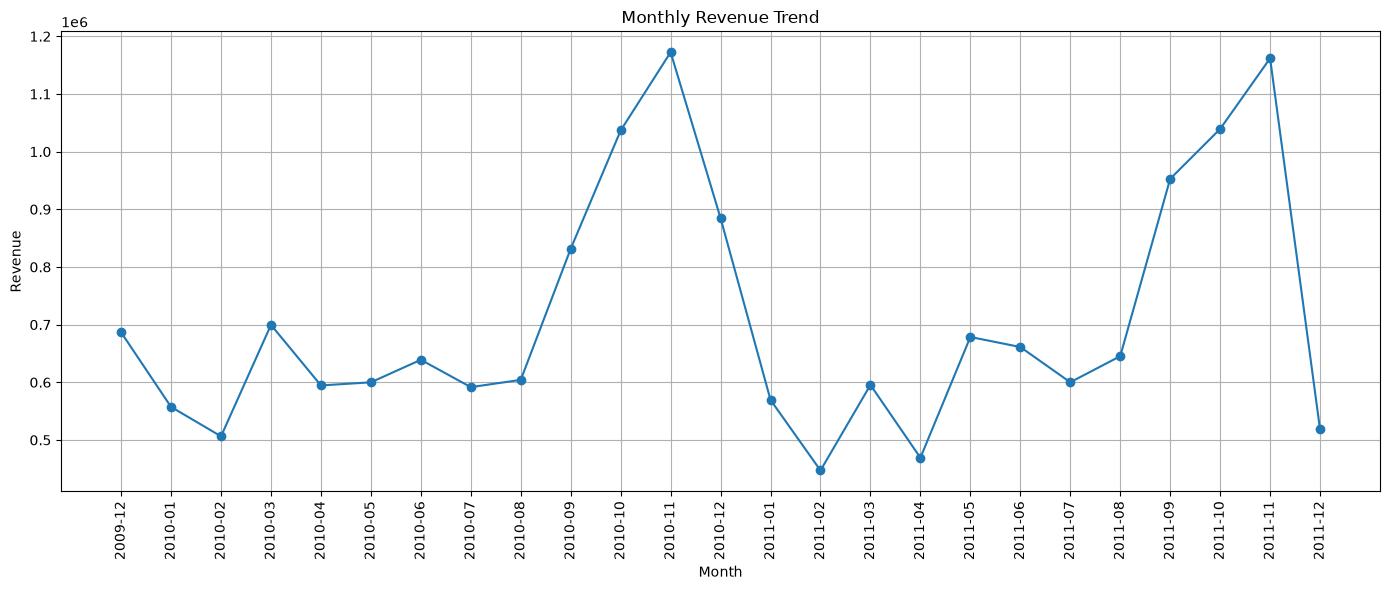

In [25]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue["Month"],
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

### Monthly Revenue Trend Findings

The monthly revenue analysis shows fluctuations in business performance throughout the analysis period.

Key observations:

- November 2010 recorded the highest monthly revenue at approximately 1.17 million.
- November 2011 recorded another strong revenue performance at approximately 1.16 million.
- February 2011 recorded the lowest monthly revenue at approximately 0.45 million.
- Revenue increased significantly between August and November in both 2010 and 2011.
- December 2011 shows lower revenue because the dataset contains records only up to December 9, 2011.

The analysis indicates that revenue varied considerably across months, with November showing particularly strong performance in both years.

The business could investigate seasonal purchasing patterns and factors contributing to monthly revenue fluctuations.

In [26]:
country_analysis = (
    sales_df.groupby("country")
    .agg(
        Revenue=("line_total", "sum"),
        Total_Orders=("invoice", "nunique"),
        Total_Customers=("customer_id", "nunique"),
        Units_Sold=("quantity", "sum")
    )
    .reset_index()
)

country_analysis = country_analysis.sort_values(
    by="Revenue",
    ascending=False
)

country_analysis.head(15)

,country,Revenue,Total_Orders,Total_Customers,Units_Sold
38,United Kingdom,14723147.50,33541,5350,8705296
10,EIRE,621631.11,567,5,321703
24,Netherlands,554232.34,228,22,383977
14,Germany,431262.46,789,107,227982
13,France,355257.47,614,95,273674
0,Australia,169968.11,95,15,104090
32,Spain,109178.53,154,41,50796
34,Switzerland,100365.34,90,22,52337
33,Sweden,91549.72,104,19,88512
9,Denmark,69862.19,43,12,237925


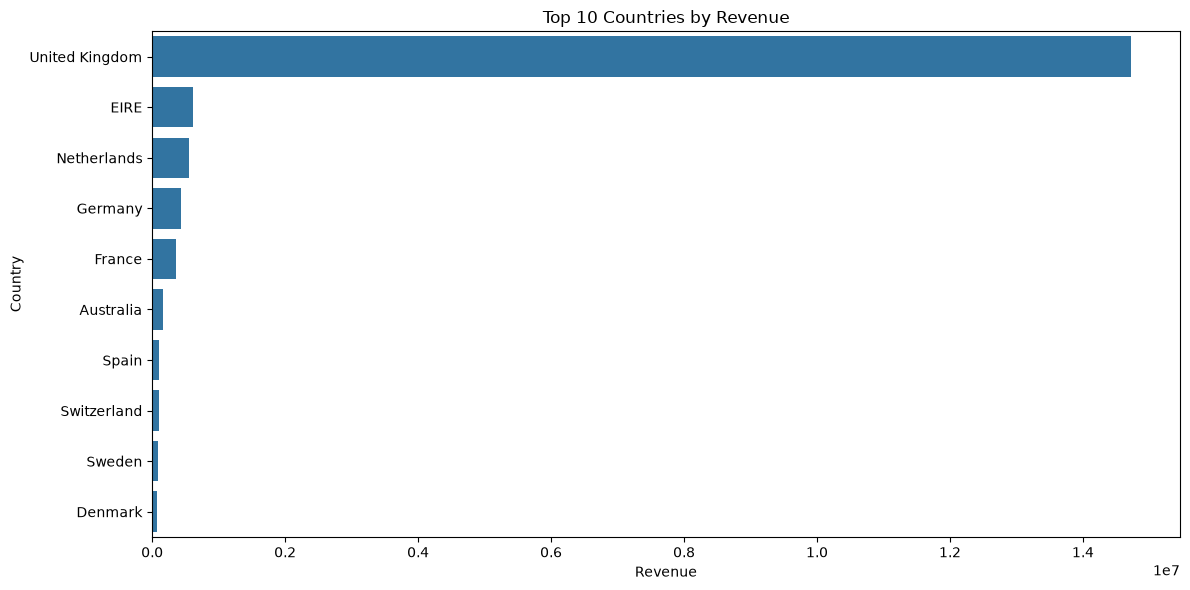

In [27]:
top_10_countries = country_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_countries,
    x="Revenue",
    y="country"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Country-wise Revenue Findings

The country-wise revenue analysis identifies the geographical markets contributing the most revenue to the business.

Key observations:

- United Kingdom is the largest revenue-generating market, contributing approximately 14.7 million.
- EIRE is the second-highest revenue contributor.
- Netherlands ranks third.
- Germany and France are also among the top revenue-generating countries.
- The United Kingdom contributes substantially more revenue than the other countries in the top 10.

The results indicate that the business depends heavily on the United Kingdom market for its revenue.

The business could investigate opportunities to strengthen its presence in other international markets while maintaining its strong position in the United Kingdom.

In [29]:
product_analysis = (
    sales_df.groupby("stock_code")
    .agg(
        Revenue=("line_total", "sum"),
        Units_Sold=("quantity", "sum"),
        Total_Orders=("invoice", "nunique"),
        Description=("description", "first")
    )
    .reset_index()
)

product_analysis = product_analysis.sort_values(
    by="Revenue",
    ascending=False
)

product_analysis.head(5)

,stock_code,Revenue,Units_Sold,Total_Orders,Description
1609,22423,286486.30,24899,3317,REGENCY CAKESTAND 3 TIER
4080,85123A,252227.81,93697,4895,WHITE HANGING HEART T-LIGHT HOLDER
4058,85099B,170616.68,94983,3260,JUMBO BAG RED WHITE SPOTTY
2726,23843,168469.60,80995,1,"PAPER CRAFT , LITTLE BIRDIE"
4625,M,152340.57,9803,620,Manual


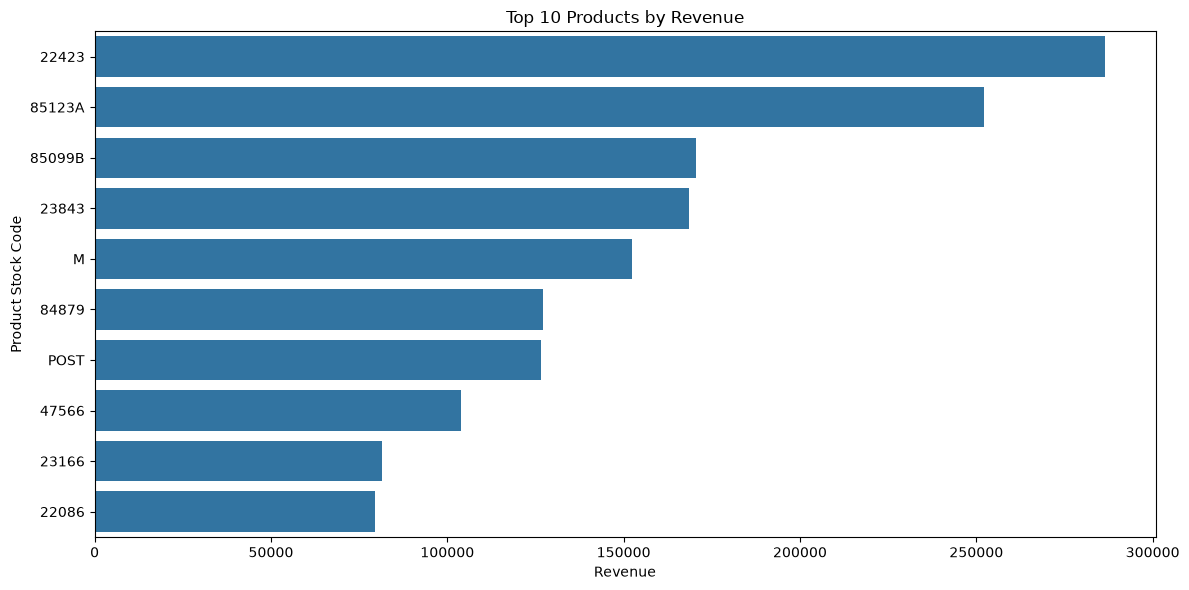

In [30]:
top_10_products = product_analysis.head(10).copy()

top_10_products["Product"] = (
    top_10_products["stock_code"].astype(str)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_products,
    x="Revenue",
    y="Product"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Stock Code")
plt.tight_layout()
plt.show()

In [31]:
customer_analysis = (
    sales_df.groupby("customer_id")
    .agg(
        Total_Revenue=("line_total", "sum"),
        Total_Orders=("invoice", "nunique"),
        Total_Units=("quantity", "sum"),
        First_Purchase=("invoice_date", "min"),
        Last_Purchase=("invoice_date", "max")
    )
    .reset_index()
)

customer_analysis = customer_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

customer_analysis.head(15)

,customer_id,Total_Revenue,Total_Orders,Total_Units,First_Purchase,Last_Purchase
5692,18102,608821.65,145,188340,2009-12-01 09:24:00,2011-12-09 11:50:00
2277,14646,528602.52,151,367193,2009-12-02 16:52:00,2011-12-08 12:12:00
1789,14156,313946.37,156,165992,2009-12-01 12:30:00,2011-11-30 10:54:00
2538,14911,295972.63,398,149987,2009-12-01 11:41:00,2011-12-08 15:54:00
5050,17450,246973.09,51,84720,2010-09-27 16:59:00,2011-12-01 13:29:00
1331,13694,196482.81,143,189205,2009-12-04 15:26:00,2011-12-06 09:32:00
5109,17511,175603.55,60,119656,2009-12-02 10:52:00,2011-12-07 10:12:00
4061,16446,168472.50,2,80997,2011-05-18 09:52:00,2011-12-09 09:15:00
4295,16684,147142.77,55,104810,2009-12-07 12:56:00,2011-12-05 14:06:00
68,12415,144458.37,28,91447,2010-06-30 08:30:00,2011-11-15 14:22:00


In [32]:
total_customers = customer_analysis["customer_id"].nunique()

repeat_customers = (
    customer_analysis[
        customer_analysis["Total_Orders"] > 1
    ]["customer_id"].nunique()
)

one_time_customers = total_customers - repeat_customers

repeat_rate = (
    repeat_customers / total_customers
) * 100

print("Total Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("One-time Customers:", one_time_customers)
print(f"Repeat Purchase Rate: {repeat_rate:.2f}%")

Total Customers: 5878
Repeat Customers: 4255
One-time Customers: 1623
Repeat Purchase Rate: 72.39%


Business 

72.39% of identifiable customers made more than one purchase. The remaining 27.61% purchased only once. The business could investigate opportunities to encourage one-time customers to return.

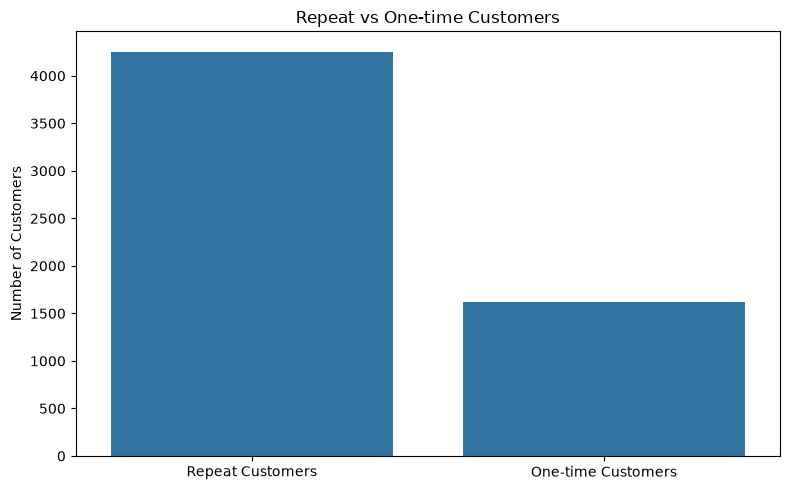

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Repeat Customers", "One-time Customers"],
    y=[repeat_customers, one_time_customers]
)

plt.title("Repeat vs One-time Customers")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Customer Purchasing Behaviour Findings

The analysis identified 5,878 customers.

- Repeat Customers: 4,255.
- One-time Customers: 1,623.
- Repeat Purchase Rate: 72.39%.

Approximately 72.39% of identifiable customers placed more than one unique order.

The remaining 27.61% purchased only once.

This indicates that repeat purchasing is an important part of the business's customer activity.

The business could investigate opportunities to encourage one-time customers to make additional purchases.

In [34]:
# Create invoice month
sales_df["invoice_month"] = (
    sales_df["invoice_date"].dt.to_period("M")
)

# Find each customer's first purchase month
sales_df["cohort_month"] = (
    sales_df.groupby("customer_id")["invoice_month"]
    .transform("min")
)

# Calculate the number of months since first purchase
sales_df["cohort_index"] = (
    (sales_df["invoice_month"].dt.year -
     sales_df["cohort_month"].dt.year) * 12
    +
    (sales_df["invoice_month"].dt.month -
     sales_df["cohort_month"].dt.month)
    + 1
)

print("Cohort columns created successfully!")

sales_df[
    ["customer_id", "invoice_month",
     "cohort_month", "cohort_index"]
].head(10)

Cohort columns created successfully!


,customer_id,invoice_month,cohort_month,cohort_index
0,13085,2009-12,2009-12,1
1,13085,2009-12,2009-12,1
2,13085,2009-12,2009-12,1
3,13085,2009-12,2009-12,1
4,13085,2009-12,2009-12,1
5,13085,2009-12,2009-12,1
6,13085,2009-12,2009-12,1
7,13085,2009-12,2009-12,1
8,13085,2009-12,2009-12,1
9,13085,2009-12,2009-12,1


In [35]:
# Count unique customers in each cohort and month
cohort_data = (
    sales_df.groupby(
        ["cohort_month", "cohort_index"]
    )["customer_id"]
    .nunique()
    .reset_index()
)

# Create cohort retention matrix
cohort_counts = cohort_data.pivot(
    index="cohort_month",
    columns="cohort_index",
    values="customer_id"
)

cohort_counts.head(10)

cohort_index,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
cohort_month,,,,,,,,,,,,,,,,,,,,,
2009-12,955.0,337.0,319.0,406.0,363.0,343.0,360.0,327.0,321.0,346.0,...,289.0,251.0,289.0,270.0,248.0,244.0,301.0,291.0,389.0,188.0
2010-01,383.0,79.0,119.0,117.0,101.0,115.0,99.0,88.0,107.0,122.0,...,58.0,90.0,76.0,71.0,75.0,93.0,74.0,94.0,22.0,NaN
2010-02,374.0,89.0,84.0,109.0,92.0,75.0,72.0,107.0,95.0,103.0,...,75.0,60.0,61.0,54.0,86.0,86.0,61.0,22.0,NaN,NaN
2010-03,443.0,84.0,102.0,107.0,103.0,90.0,109.0,134.0,122.0,48.0,...,75.0,77.0,69.0,78.0,89.0,94.0,35.0,NaN,NaN,NaN
2010-04,294.0,57.0,57.0,48.0,54.0,66.0,81.0,77.0,31.0,32.0,...,46.0,41.0,44.0,53.0,66.0,17.0,NaN,NaN,NaN,NaN
2010-05,254.0,40.0,43.0,44.0,45.0,65.0,54.0,32.0,15.0,21.0,...,32.0,35.0,42.0,39.0,12.0,NaN,NaN,NaN,NaN,NaN
2010-06,270.0,47.0,51.0,55.0,62.0,77.0,34.0,24.0,22.0,32.0,...,33.0,36.0,55.0,14.0,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,186.0,29.0,34.0,55.0,54.0,26.0,21.0,27.0,27.0,21.0,...,32.0,44.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,162.0,33.0,48.0,52.0,28.0,19.0,16.0,20.0,22.0,21.0,...,32.0,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [36]:
# Calculate retention percentage
cohort_sizes = cohort_counts.iloc[:, 0]

retention = cohort_counts.divide(
    cohort_sizes, axis=0
) * 100

retention = retention.round(2)

retention.head(10)

cohort_index,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
cohort_month,,,,,,,,,,,,,,,,,,,,,
2009-12,100.0,35.29,33.40,42.51,38.01,35.92,37.70,34.24,33.61,36.23,...,30.26,26.28,30.26,28.27,25.97,25.55,31.52,30.47,40.73,19.69
2010-01,100.0,20.63,31.07,30.55,26.37,30.03,25.85,22.98,27.94,31.85,...,15.14,23.50,19.84,18.54,19.58,24.28,19.32,24.54,5.74,NaN
2010-02,100.0,23.80,22.46,29.14,24.60,20.05,19.25,28.61,25.40,27.54,...,20.05,16.04,16.31,14.44,22.99,22.99,16.31,5.88,NaN,NaN
2010-03,100.0,18.96,23.02,24.15,23.25,20.32,24.60,30.25,27.54,10.84,...,16.93,17.38,15.58,17.61,20.09,21.22,7.90,NaN,NaN,NaN
2010-04,100.0,19.39,19.39,16.33,18.37,22.45,27.55,26.19,10.54,10.88,...,15.65,13.95,14.97,18.03,22.45,5.78,NaN,NaN,NaN,NaN
2010-05,100.0,15.75,16.93,17.32,17.72,25.59,21.26,12.60,5.91,8.27,...,12.60,13.78,16.54,15.35,4.72,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.41,18.89,20.37,22.96,28.52,12.59,8.89,8.15,11.85,...,12.22,13.33,20.37,5.19,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.59,18.28,29.57,29.03,13.98,11.29,14.52,14.52,11.29,...,17.20,23.66,8.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,20.37,29.63,32.10,17.28,11.73,9.88,12.35,13.58,12.96,...,19.75,6.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


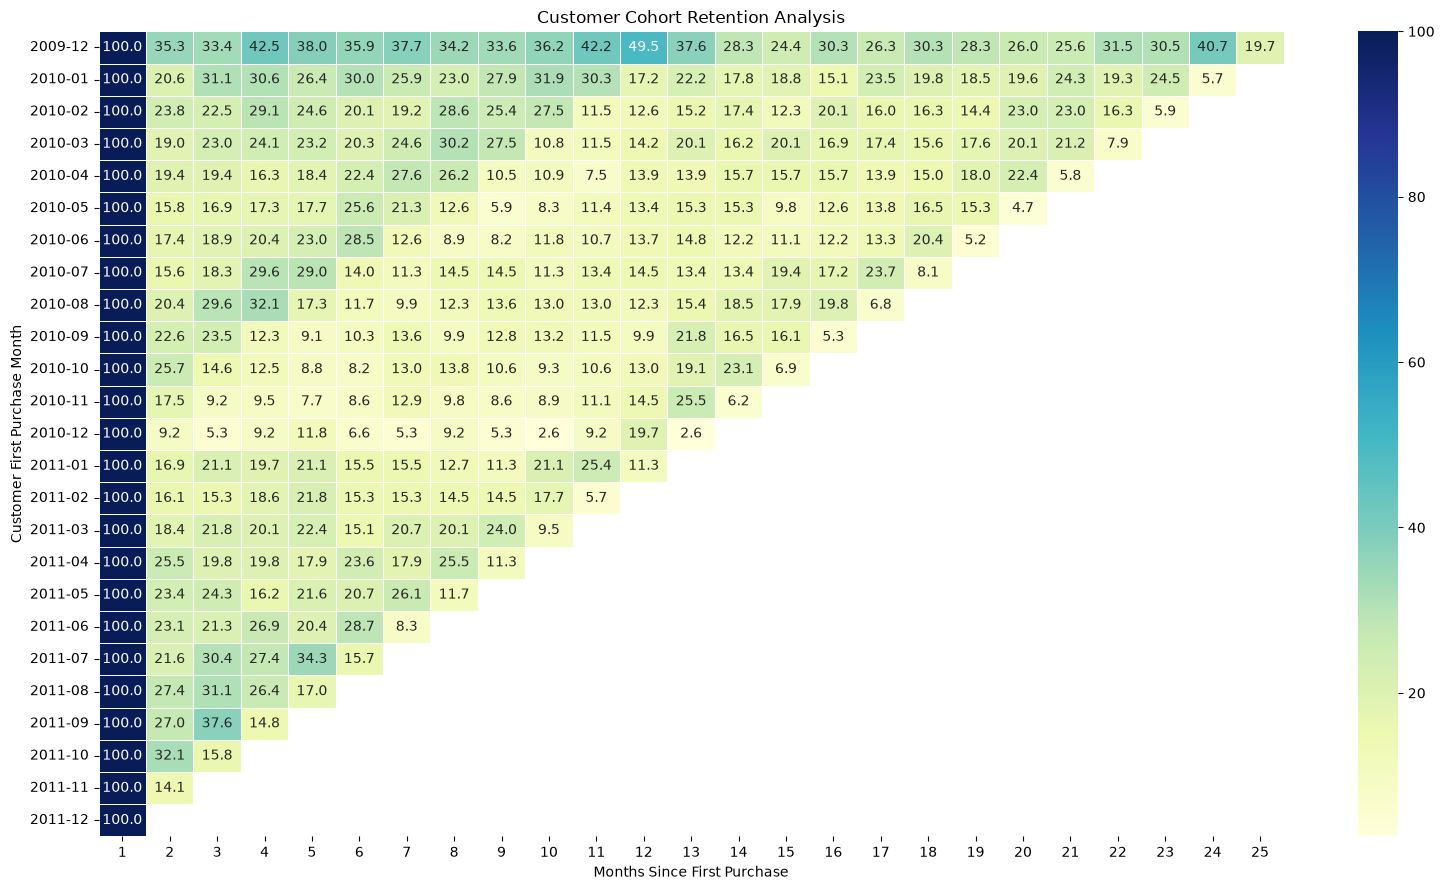

In [37]:
plt.figure(figsize=(16, 9))

sns.heatmap(
    retention,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Customer Cohort Retention Analysis")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer First Purchase Month")

plt.tight_layout()
plt.show()

### Cohort Retention Findings

Cohort analysis was performed by grouping customers according to their first purchase month.

The retention heatmap shows the percentage of customers from each cohort who made purchases in subsequent months.

Key observations:

- The December 2009 cohort had 35.29% retention in month 2.
- Its retention increased to 42.51% in month 4.
- Its retention was 49.50% in month 12.
- Retention percentages fluctuate across different cohorts and months.

This indicates that customer purchasing activity does not decline continuously. Some customers return after periods without purchases.

The analysis measures monthly purchasing activity rather than continuous customer retention.

Blank cells represent months outside the available observation period.

In [38]:
# Set analysis date as one day after the last transaction
analysis_date = sales_df["invoice_date"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics
rfm = (
    sales_df.groupby("customer_id")
    .agg(
        Recency=("invoice_date", lambda x: (analysis_date - x.max()).days),
        Frequency=("invoice", "nunique"),
        Monetary=("line_total", "sum")
    )
    .reset_index()
)

rfm.head(10)

,customer_id,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,5633.32
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40
5,12351,375,1,300.93
6,12352,36,10,2849.84
7,12353,204,2,406.76
8,12354,232,1,1079.40
9,12355,214,2,947.61


In [39]:
print("Total Customers:", len(rfm))

print("\nRFM Summary:")
print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

Total Customers: 5878

RFM Summary:
       Recency  Frequency   Monetary
count  5878.00    5878.00    5878.00
mean    201.33       6.29    3018.62
std     209.34      13.01   14737.73
min       1.00       1.00       2.95
25%      26.00       1.00     348.76
50%      96.00       3.00     898.92
75%     380.00       7.00    2307.09
max     739.00     398.00  608821.65


In [40]:
# Create RFM scores from 1 to 5

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm.head(10)

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346,326,12,77556.46,2,5,5
1,12347,2,8,5633.32,5,4,5
2,12348,75,5,2019.40,3,4,4
3,12349,19,4,4428.69,5,3,5
4,12350,310,1,334.40,2,1,2
5,12351,375,1,300.93,2,1,2
6,12352,36,10,2849.84,4,5,4
7,12353,204,2,406.76,2,2,2
8,12354,232,1,1079.40,2,1,3
9,12355,214,2,947.61,2,2,3


In [41]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm["RFM_Total"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

rfm.head(10)

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
0,12346,326,12,77556.46,2,5,5,255,12
1,12347,2,8,5633.32,5,4,5,545,14
2,12348,75,5,2019.40,3,4,4,344,11
3,12349,19,4,4428.69,5,3,5,535,13
4,12350,310,1,334.40,2,1,2,212,5
5,12351,375,1,300.93,2,1,2,212,5
6,12352,36,10,2849.84,4,5,4,454,13
7,12353,204,2,406.76,2,2,2,222,6
8,12354,232,1,1079.40,2,1,3,213,6
9,12355,214,2,947.61,2,2,3,223,7


In [42]:
def segment_customer(row):

    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"

    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customers"

    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "New / Promising"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    else:
        return "Needs Attention"


rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

rfm.head(15)

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Customer_Segment
0,12346,326,12,77556.46,2,5,5,255,12,At Risk
1,12347,2,8,5633.32,5,4,5,545,14,Champions
2,12348,75,5,2019.40,3,4,4,344,11,Loyal Customers
3,12349,19,4,4428.69,5,3,5,535,13,Needs Attention
4,12350,310,1,334.40,2,1,2,212,5,Needs Attention
5,12351,375,1,300.93,2,1,2,212,5,Needs Attention
6,12352,36,10,2849.84,4,5,4,454,13,Champions
7,12353,204,2,406.76,2,2,2,222,6,Needs Attention
8,12354,232,1,1079.40,2,1,3,213,6,Needs Attention
9,12355,214,2,947.61,2,2,3,223,7,Needs Attention


### RFM Customer Segmentation Rules

Customers are classified using the following conditions:

- Champions: Recency score >= 4, Frequency score >= 4, Monetary score >= 4.
- Loyal Customers: Recency score >= 3 and Frequency score >= 4, excluding Champions.
- New / Promising: Recency score >= 4 and Frequency score <= 2.
- At Risk: Recency score <= 2 and Frequency score >= 3.
- Needs Attention: Customers who do not meet the above conditions.

The segmentation rules are designed to group customers according to their recent purchasing activity, purchase frequency and spending behaviour.

### RFM Customer Analysis Findings

The RFM analysis measures customer purchasing behaviour using three metrics:

- Recency: Number of days since the customer's last purchase.
- Frequency: Number of unique orders placed by the customer.
- Monetary: Total revenue generated by the customer.

Observations from the sample:

- Customer 12346 generated the highest monetary value of 77,556.46, despite having a recency of 326 days.
- Customer 12347 purchased recently, with a recency of 2 days, and placed 8 orders.
- Customer 12352 placed 10 orders, indicating frequent purchasing behaviour.
- Customers 12350 and 12351 placed only one order each and have relatively high recency values.

These examples demonstrate that customers with high historical spending are not necessarily the most recently active customers.

RFM analysis helps the business identify valuable customers, frequent purchasers and customers who may need re-engagement.

In [43]:
segment_summary = (
    rfm.groupby("Customer_Segment")
    .agg(
        Total_Customers=("customer_id", "count"),
        Total_Revenue=("Monetary", "sum")
    )
    .reset_index()
)

segment_summary["Customer_Percentage"] = (
    segment_summary["Total_Customers"] /
    len(rfm) * 100
).round(2)

segment_summary = segment_summary.sort_values(
    by="Total_Customers",
    ascending=False
)

segment_summary

,Customer_Segment,Total_Customers,Total_Revenue,Customer_Percentage
3,Needs Attention,2615,1701052.86,44.49
1,Champions,1292,12087432.74,21.98
0,At Risk,825,1634975.76,14.04
2,Loyal Customers,705,1925757.95,11.99
4,New / Promising,441,394209.85,7.50


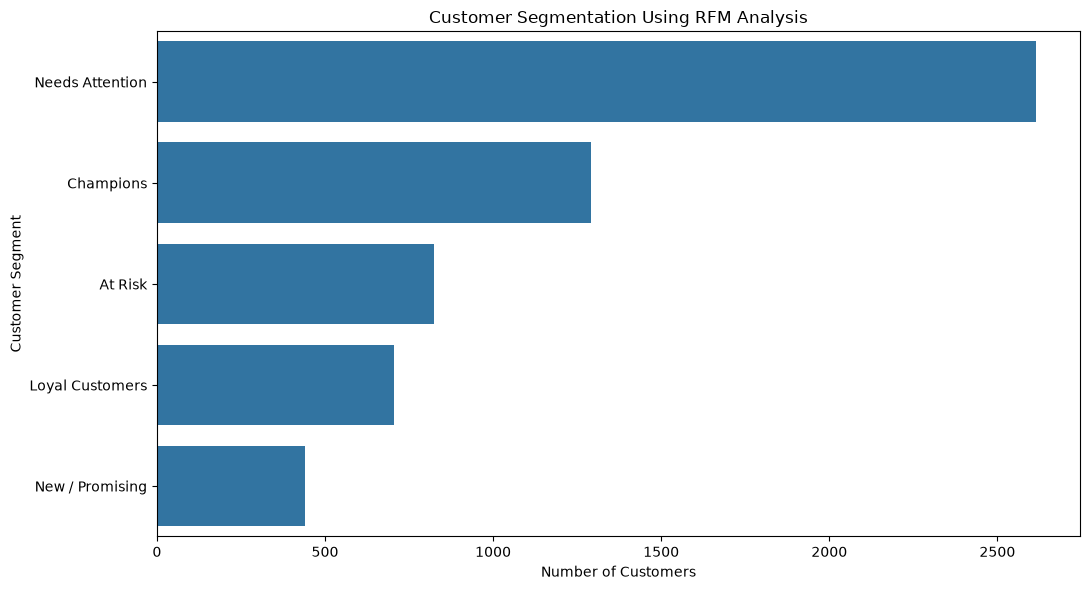

In [44]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_summary,
    x="Total_Customers",
    y="Customer_Segment"
)

plt.title("Customer Segmentation Using RFM Analysis")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

### Customer Segmentation Findings

The RFM analysis classified 5,878 customers into five segments.

| Customer Segment | Customers | Percentage |
|---|---:|---:|
| Needs Attention | 2,615 | 44.49% |
| Champions | 1,292 | 21.98% |
| At Risk | 825 | 14.04% |
| Loyal Customers | 705 | 11.99% |
| New / Promising | 441 | 7.50% |

Needs Attention is the largest customer segment, representing 44.49% of the customer base.

Champions represent 21.98% of customers.

This segmentation provides a way to identify different customer groups and consider appropriate retention strategies.

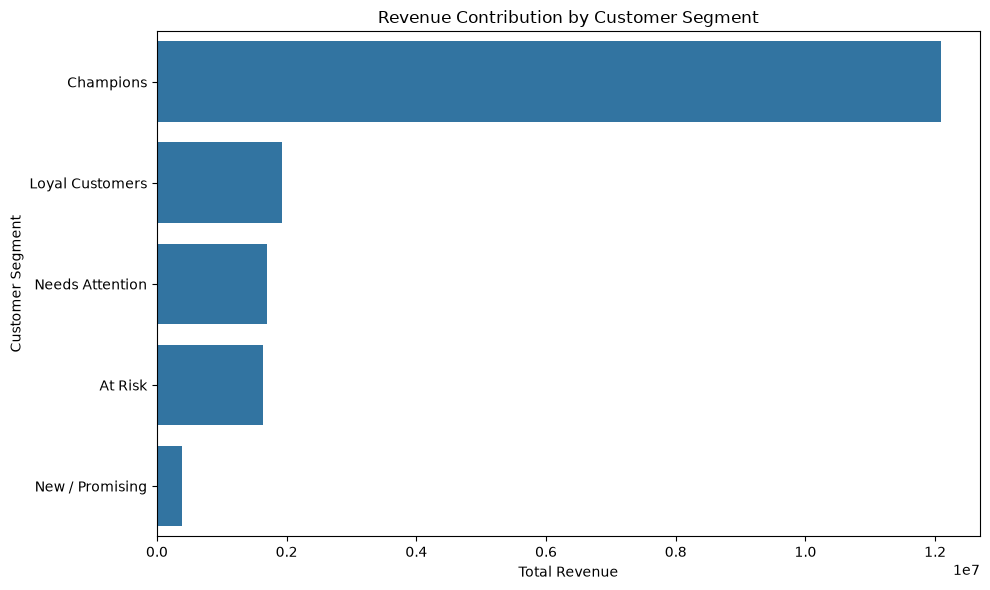

In [45]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary.sort_values(
        by="Total_Revenue",
        ascending=False
    ),
    x="Total_Revenue",
    y="Customer_Segment"
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Total Revenue")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

### Revenue Contribution Findings

The revenue contribution analysis shows that Champions generate the highest revenue among all customer segments.

- Champions: 12,087,432.74
- Loyal Customers: 1,925,757.95
- Needs Attention: 1,701,052.86
- At Risk: 1,634,975.76
- New / Promising: 394,209.85

Champions contribute approximately 68.1% of total revenue while representing only 21.98% of customers.

This indicates that a relatively small customer segment contributes a substantial share of business revenue.

The business could consider loyalty programmes and personalised engagement to maintain relationships with these valuable customers.

## 12. Key Business Findings and Recommendations

### Key Findings

1. The clean sales dataset contains 805,531 transaction lines.
2. Total revenue from the selected sales records is 17,743,429.16.
3. The business has 5,878 identifiable customers.
4. The repeat purchase rate is 72.39%.
5. Customer cohort analysis shows that monthly retention varies across cohorts.
6. RFM analysis identifies Champions as a particularly valuable customer segment.
7. The Needs Attention segment represents the largest number of customers.

### Business Recommendations

1. Investigate opportunities to encourage one-time customers to make repeat purchases.
2. Consider loyalty programmes and personalised engagement for Champions.
3. Investigate re-engagement strategies for At Risk customers.
4. Review the purchasing behaviour of customers in the Needs Attention segment.
5. Monitor monthly revenue and customer retention to identify changes in business performance.

### Conclusion

The analysis provides an overview of sales performance, customer purchasing behaviour and retention patterns.

RFM segmentation helps identify valuable customer groups and potential opportunities for improving customer engagement and retention.

# Final Conclusion

This project analysed the Online Retail II dataset to understand sales performance, product performance, customer purchasing behaviour and customer retention.

Python was used for data exploration, data quality assessment, filtering, business analysis, cohort retention and RFM customer segmentation.

The analysis identified several important findings:

1. The filtered sales dataset contains 805,531 transaction lines.
2. Total revenue from the selected sales records is 17,743,429.16.
3. The business has 5,878 identifiable customers.
4. The repeat purchase rate is 72.39%.
5. Customer retention varies across different purchase cohorts.
6. Champions contribute approximately 68.1% of revenue.
7. Needs Attention is the largest RFM customer segment.

Based on these findings, the business could investigate ways to improve repeat purchases, strengthen customer loyalty and re-engage customers who have not purchased recently.

The project demonstrates how transaction data can be transformed into meaningful business insights using Python.

In [46]:
# Create an Excel file containing Python analysis results

with pd.ExcelWriter(
    "Project_2_Python_Analysis_Results.xlsx",
    engine="openpyxl"
) as writer:

    monthly_revenue.to_excel(
        writer, sheet_name="Monthly Revenue", index=False
    )

    country_analysis.to_excel(
        writer, sheet_name="Country Analysis", index=False
    )

    product_analysis.to_excel(
        writer, sheet_name="Product Analysis", index=False
    )

    customer_analysis.to_excel(
        writer, sheet_name="Customer Analysis", index=False
    )

    cohort_counts.to_excel(
        writer, sheet_name="Cohort Counts"
    )

    retention.to_excel(
        writer, sheet_name="Cohort Retention"
    )

    rfm.to_excel(
        writer, sheet_name="RFM Analysis", index=False
    )

    segment_summary.to_excel(
        writer, sheet_name="Customer Segments", index=False
    )

print("Python analysis results exported successfully!")

Python analysis results exported successfully!
